Saved → results/residual_rl_reward_rate_comparison.pdf / .png


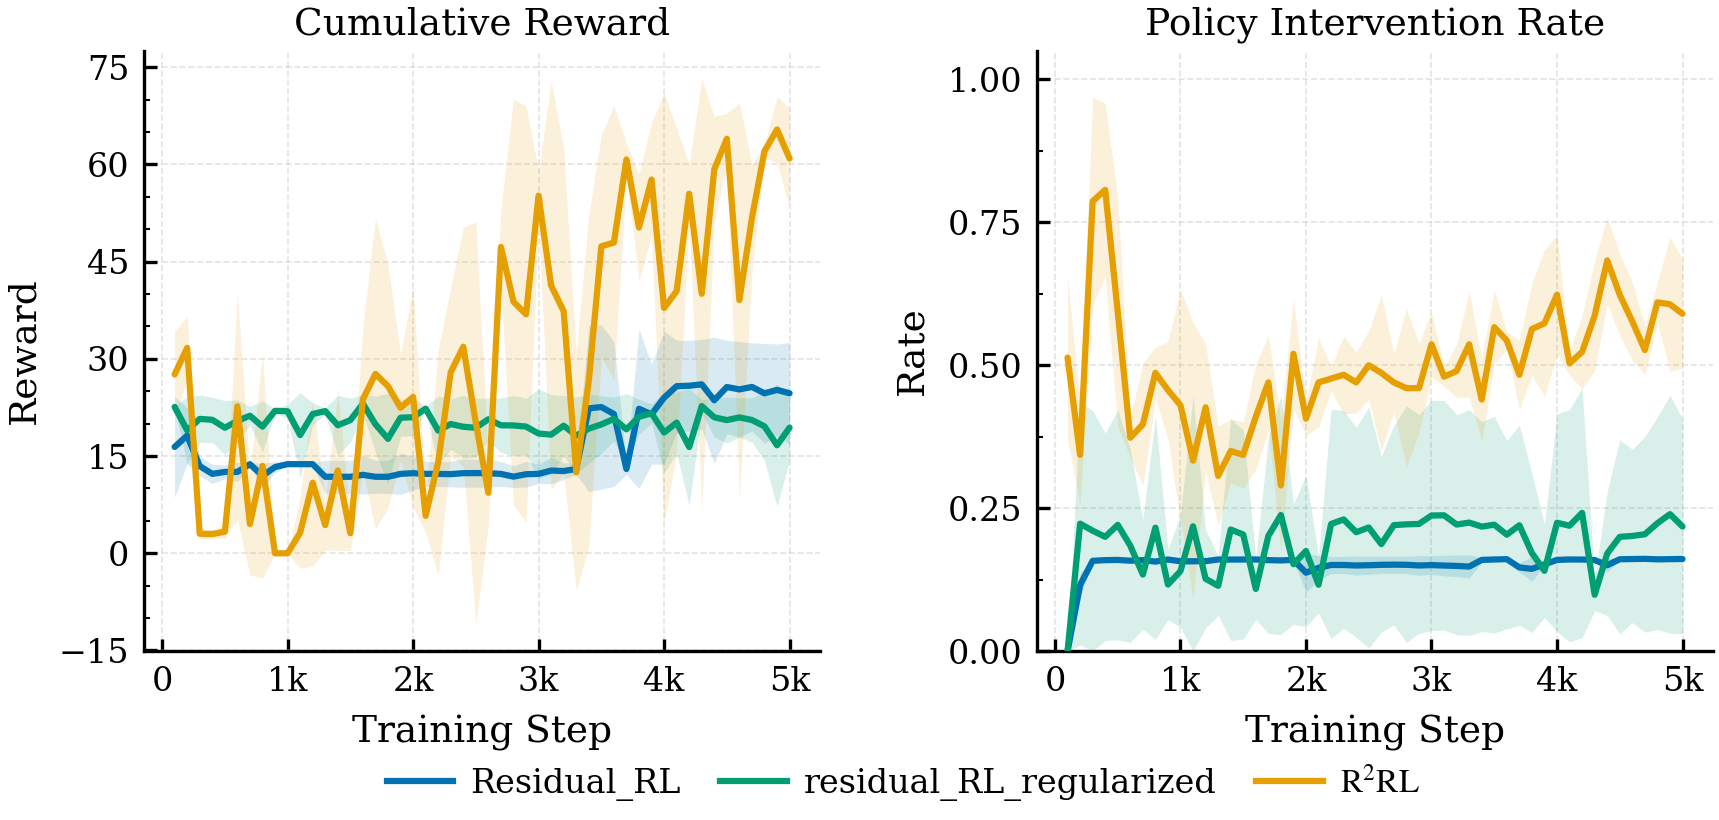

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from scipy.ndimage import uniform_filter1d


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def smooth(x, w=7):
    x = np.asarray(x, dtype=float)
    if len(x) < w:
        return x
    return uniform_filter1d(x, size=w, mode="nearest")


def aggregate_runs(dfs):
    """
    Merge runs by common training steps and compute mean/std.
    """
    merged = None

    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(
            columns={"Value": f"v{i}"}
        )

        if merged is None:
            merged = tmp
        else:
            merged = pd.merge(
                merged,
                tmp,
                on="Step",
                how="inner"
            )

    merged = merged.sort_values("Step")

    steps = merged["Step"].to_numpy()

    values = merged.drop(
        columns=["Step"]
    ).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


# ══════════════════════════════════════════════════════════════════════════
# LOAD reward DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen reward ----------------
df111 = pd.read_csv("./results/residualRL/rewards/ResidualRL-scale0.1.csv")
df112 = pd.read_csv("./results/residualRL/rewards/ResidualRL1-scale0.1.csv")

df131 = pd.read_csv("./results/residualRL/rewards/stoch_iql_ddpg_bc_OSResidualRL1.csv")
df132 = pd.read_csv("./results/residualRL/rewards/stoch_iql_ddpg_bc_OSResidualRL2.csv")

df141 = pd.read_csv("./results/iql/2.40.csv")
df142 = pd.read_csv("./results/iql/2.41.csv")
df143 = pd.read_csv("./results/iql/2.42.csv")



# ══════════════════════════════════════════════════════════════════════════
# LOAD rate DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen rate ----------------
df221 = pd.read_csv("./results/residualRL/rates/ResidualRL-scale0.1.csv")
df222 = pd.read_csv("./results/residualRL/rates/ResidualRL1-scale0.1.csv")

df231 = pd.read_csv("./results/residualRL/rates/stoch_iql_ddpg_bc_OSResidualRL1.csv")
df232 = pd.read_csv("./results/residualRL/rates/stoch_iql_ddpg_bc_OSResidualRL2.csv")

df241 = pd.read_csv("./results/rate_iql/2.40.csv")
df242 = pd.read_csv("./results/rate_iql/2.41.csv")
df243 = pd.read_csv("./results/rate_iql/2.42.csv")

# ══════════════════════════════════════════════════════════════════════════
# Reward GROUPS
# ══════════════════════════════════════════════════════════════════════════
reward_groups = [
    ("Residual_RL", [df111, df112]),
    ("residual_RL_regularized", [df131, df132]),
    ("OSRL", [df141, df142, df143]),
]

# openbox_groups = [
#     ("IBRL (1 demo)",  [df221, df222, df223]),
#     ("IBRL (10 demos)", [df231, df232]),
#     ("OSRL", [df241, df242, df243]),
# ]

# ══════════════════════════════════════════════════════════════════════════
# Rate GROUPS
# ══════════════════════════════════════════════════════════════════════════
rate_groups = [
    ("Residual_RL", [df221, df222]),
    ("residual_RL_regularized", [df231, df232]),
    ("OSRL", [df241, df242, df243]),
]

# openbox_groups = [
#     ("IBRL (1 demo)",  [df221, df222, df223]),
#     ("IBRL (10 demos)", [df231, df232]),
#     ("OSRL", [df431, df432, df433]),
# ]

# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)


def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std



# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE  (IEEE / NeurIPS / ICML)
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    # --- font ---
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset":   "stix",          # matches Times in math mode
    "font.size":          9,
    "axes.titlesize":     9,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "legend.title_fontsize": 8,

    # --- lines / markers ---
    "lines.linewidth":    1.5,
    "patch.linewidth":    0.5,

    # --- axes ---
    "axes.linewidth":     0.8,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.grid":          True,
    "grid.linestyle":     "--",
    "grid.linewidth":     0.4,
    "grid.alpha":         0.4,
    "grid.color":         "#bbbbbb",

    # --- ticks ---
    "xtick.direction":    "in",
    "ytick.direction":    "in",
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.major.size":   3.0,
    "ytick.major.size":   3.0,

    # --- output ---
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

# ── Colorblind-safe palette (Wong 2011) ───────────────────────────────────
COLORS = {
    "Residual_RL": "#0072B2",              # blue
    "residual_RL_regularized": "#009E73",  # green
    "OSRL": "#E69F00",                    # amber
}

REWARD_OFFSETS = {
    "Residual_RL": 10.0,
    "residual_RL_regularized": 10.0,
    "OSRL": 0.0,
}

DASHES = {
    "Residual_RL": (None, None),
    "residual_RL_regularized": (None, None),
    "OSRL": (None, None),
}

# ── Figure — two-column friendly (6.75 in wide, golden-ratio height) ──────
FIG_W, FIG_H = 6.75, 2.6
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
fig.subplots_adjust(wspace=0.32)

# ════════════════════════════════════════════════════════════
# LEFT  — Cumulative Reward
# ════════════════════════════════════════════════════════════
ax0 = axes[0]

for name, dfs in reward_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    mean = mean + REWARD_OFFSETS[name]
    c  = COLORS[name]
    ls = DASHES[name]

    ax0.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax0.fill_between(steps,
                     mean - std,
                     mean + std,
                     color=c, alpha=0.15, linewidth=0, zorder=2)


# # replay baseline
# ax0.plot(df00["Step"], df00["Value"]*0,
#          color=COLORS["replay"], linewidth=1.2,
#          linestyle=(0, (4, 1.5)),          # dash-dot-dot
#          label="Replay", zorder=3)

ax0.set_title(r"Cumulative Reward", loc="center", pad=4)
ax0.set_xlabel("Training Step")
ax0.set_ylabel("Reward")
# ax0.set_ylim(0, 34)
ax0.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax0.yaxis.set_major_locator(mticker.MultipleLocator(15))
ax0.yaxis.set_minor_locator(mticker.MultipleLocator(5))
ax0.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# RIGHT — RL Selection Rate
# ════════════════════════════════════════════════════════════
ax1 = axes[1]

for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)

    c  = COLORS[name]
    ls = DASHES[name]

    ax1.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax1.fill_between(steps,
                 np.clip(mean - std, 0.0, 1.0),
                 np.clip(mean + std, 0.0, 1.0),
                     color=c, alpha=0.15, linewidth=0, zorder=2)

ax1.set_title(r"Policy Intervention Rate", loc="center", pad=4)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Rate")
ax1.set_ylim(0, 1.05)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax1.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax1.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax1.tick_params(which="minor", length=1.5, width=0.5)


# ════════════════════════════════════════════════════════════
# SHARED LEGEND  (single legend below both panels)
# ════════════════════════════════════════════════════════════
legend_handles = [
    Line2D(
        [0], [0],
        color=COLORS[n],
        linewidth=1.5,
        dashes=DASHES[n] if DASHES[n][0] else [],
        label=r"$\mathrm{R}^{2}\mathrm{RL}$" if n == "OSRL" else n,
    )
    for n in ["Residual_RL", "residual_RL_regularized", "OSRL"]
]
# legend_handles.append(
#     Line2D([0], [0], color=COLORS["replay"], linewidth=1.2,
#            linestyle=(0, (4, 1.5)), label="Replay")
# )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
    handlelength=2.0,
    columnspacing=1.2,
    handletextpad=0.5,
)

# ════════════════════════════════════════════════════════════
# SAVE
# ════════════════════════════════════════════════════════════
out = "results/residual_rl_reward_rate_comparison"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()

Saved → results/residual_rl_box_reward_rate_comparison.pdf / .png


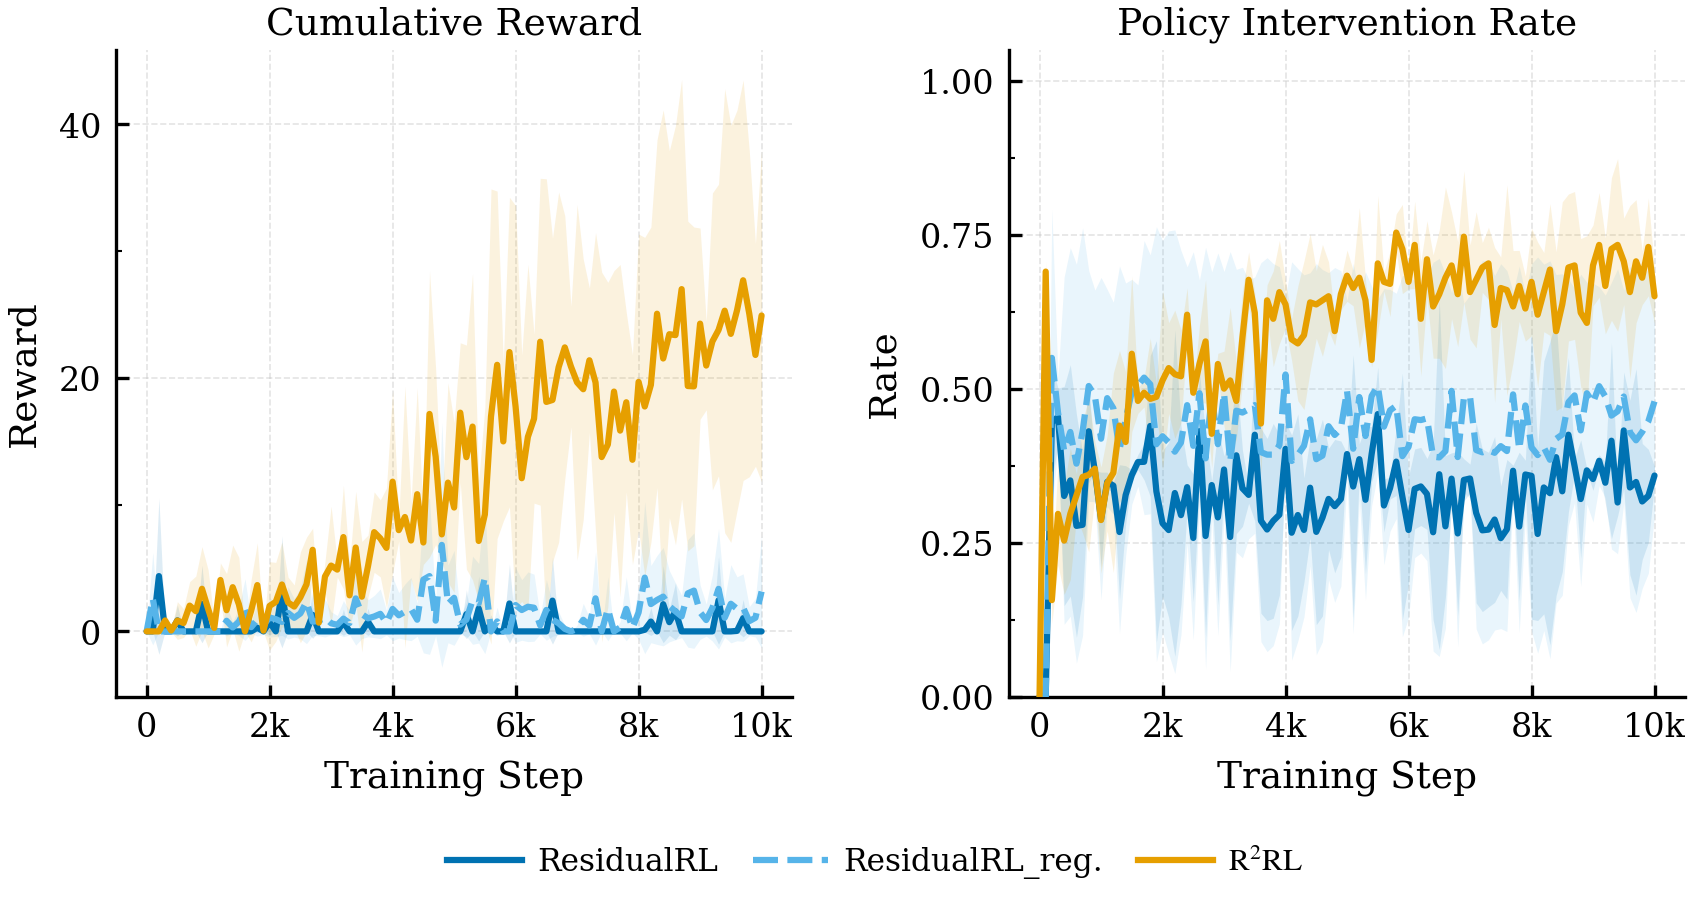

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from scipy.ndimage import uniform_filter1d


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def smooth(x, w=7):
    x = np.asarray(x, dtype=float)
    if len(x) < w:
        return x
    return uniform_filter1d(x, size=w, mode="nearest")


def aggregate_runs(dfs):
    """
    Merge runs by common training steps and compute mean/std.
    """
    merged = None

    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(
            columns={"Value": f"v{i}"}
        )

        if merged is None:
            merged = tmp
        else:
            merged = pd.merge(
                merged,
                tmp,
                on="Step",
                how="inner"
            )

    merged = merged.sort_values("Step")

    steps = merged["Step"].to_numpy()

    values = merged.drop(
        columns=["Step"]
    ).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


# ══════════════════════════════════════════════════════════════════════════
# LOAD reward DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen reward ----------------
df101 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_demo1.csv")
df102 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_demo12.csv")

df111 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_demo12.csv")
df112 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_ResidualRL_policy_td31.csv")

# df121 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_ResidualRL_policy_td3.csv")
# df122 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_ResidualRL_policy_td31.csv")

# df131 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_policy_reg.csv")
# df132 = pd.read_csv("./results/residualRL/rewards_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_policy_reg1.csv")

df141 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df142 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df143 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")


# ══════════════════════════════════════════════════════════════════════════
# LOAD rate DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen rate ----------------
df201 = pd.read_csv("./results/residualRL/rates_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_demo1.csv")
df202 = pd.read_csv("./results/residualRL/rates_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_demo12.csv")

df211 = pd.read_csv("./results/residualRL/rates_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_demo12.csv")
df212 = pd.read_csv("./results/residualRL/rates_box/residual_rl_ResidualRL_policy_td31.csv")

# df221 = pd.read_csv("./results/residualRL/rates_box/residual_rl_ResidualRL_policy_td3.csv")
# df222 = pd.read_csv("./results/residualRL/rates_box/residual_rl_ResidualRL_policy_td31.csv")

# df231 = pd.read_csv("./results/residualRL/rates_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_policy_reg.csv")
# df232 = pd.read_csv("./results/residualRL/rates_box/residual_rl_stoch_iql_ddpg_bc_ResidualRL_policy_reg1.csv")

df241 = pd.read_csv("./results/openbox/rate/2.7_awr_utd1.csv")
df242 = pd.read_csv("./results/openbox/rate/2.71_utd1.csv")
df243 = pd.read_csv("./results/openbox/rate/2.7_utd1.csv")


# ══════════════════════════════════════════════════════════════════════════
# GROUPS
# ══════════════════════════════════════════════════════════════════════════
reward_groups = [
    ("ResidualRL", [df101, df102]),
    ("ResidualRL_reg.", [df111, df112]),
    ("OSRL", [df141, df142, df143]),
]

rate_groups = [
    ("ResidualRL", [df201, df202]),
    ("ResidualRL_reg.", [df211, df212]),
    ("OSRL", [df241, df242, df243]),
]

def initialize_at_zero(steps, mean, std):
    """Make every plotted curve and uncertainty band start at (0, 0)."""
    if len(steps) and steps[0] == 0:
        mean[0] = 0.0
        std[0] = 0.0
        return steps, mean, std
    return (np.insert(steps, 0, 0),
            np.insert(mean, 0, 0.0),
            np.insert(std, 0, 0.0))


# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 7.5,
    "lines.linewidth": 1.5,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.color": "#bbbbbb",
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

COLORS = {
    "ResidualRL": "#0072B2",
    "ResidualRL_reg.": "#56B4E9",
    "OSRL": "#E69F00",
}

DASHES = {
    "ResidualRL": (),
    "ResidualRL_reg.": (4, 1.5),
    "OSRL": (),
}

FIG_W, FIG_H = 6.75, 2.8
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
fig.subplots_adjust(wspace=0.32)

# LEFT — Cumulative Reward
ax0 = axes[0]
for name, dfs in reward_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    steps, mean, std = initialize_at_zero(steps, mean, std)
    ax0.plot(steps, mean, color=COLORS[name], dashes=DASHES[name],
             solid_capstyle="round", label=name, zorder=3)
    ax0.fill_between(steps, mean - std, mean + std,
                     color=COLORS[name], alpha=0.13, linewidth=0, zorder=2)

ax0.set_title("Cumulative Reward", pad=4)
ax0.set_xlabel("Training Step")
ax0.set_ylabel("Reward")
ax0.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x / 1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax0.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax0.yaxis.set_minor_locator(mticker.MultipleLocator(10))
ax0.tick_params(which="minor", length=1.5, width=0.5)

# RIGHT — Policy Intervention Rate
ax1 = axes[1]
for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    steps, mean, std = initialize_at_zero(steps, mean, std)
    ax1.plot(steps, mean, color=COLORS[name], dashes=DASHES[name],
             solid_capstyle="round", label=name, zorder=3)
    ax1.fill_between(steps,
                     np.clip(mean - std, 0.0, 1.0),
                     np.clip(mean + std, 0.0, 1.0),
                     color=COLORS[name], alpha=0.13, linewidth=0, zorder=2)

ax1.set_title("Policy Intervention Rate", pad=4)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Rate")
ax1.set_ylim(0, 1.05)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x / 1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax1.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax1.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax1.tick_params(which="minor", length=1.5, width=0.5)

legend_order = [
    "ResidualRL",
    "ResidualRL_reg.",
    "OSRL",
]
legend_handles = [
    Line2D(
        [0], [0],
        color=COLORS[name],
        linewidth=1.5,
        dashes=DASHES[name],
        label=r"$\mathrm{R}^{2}\mathrm{RL}$" if name == "OSRL" else name,
    )
    for name in legend_order
]
fig.legend(handles=legend_handles, loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, -0.14),
           handlelength=2.4, columnspacing=1.1, handletextpad=0.5)

out = "results/residual_rl_box_reward_rate_comparison"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()


Saved → results/q_score_comparison.pdf / .png


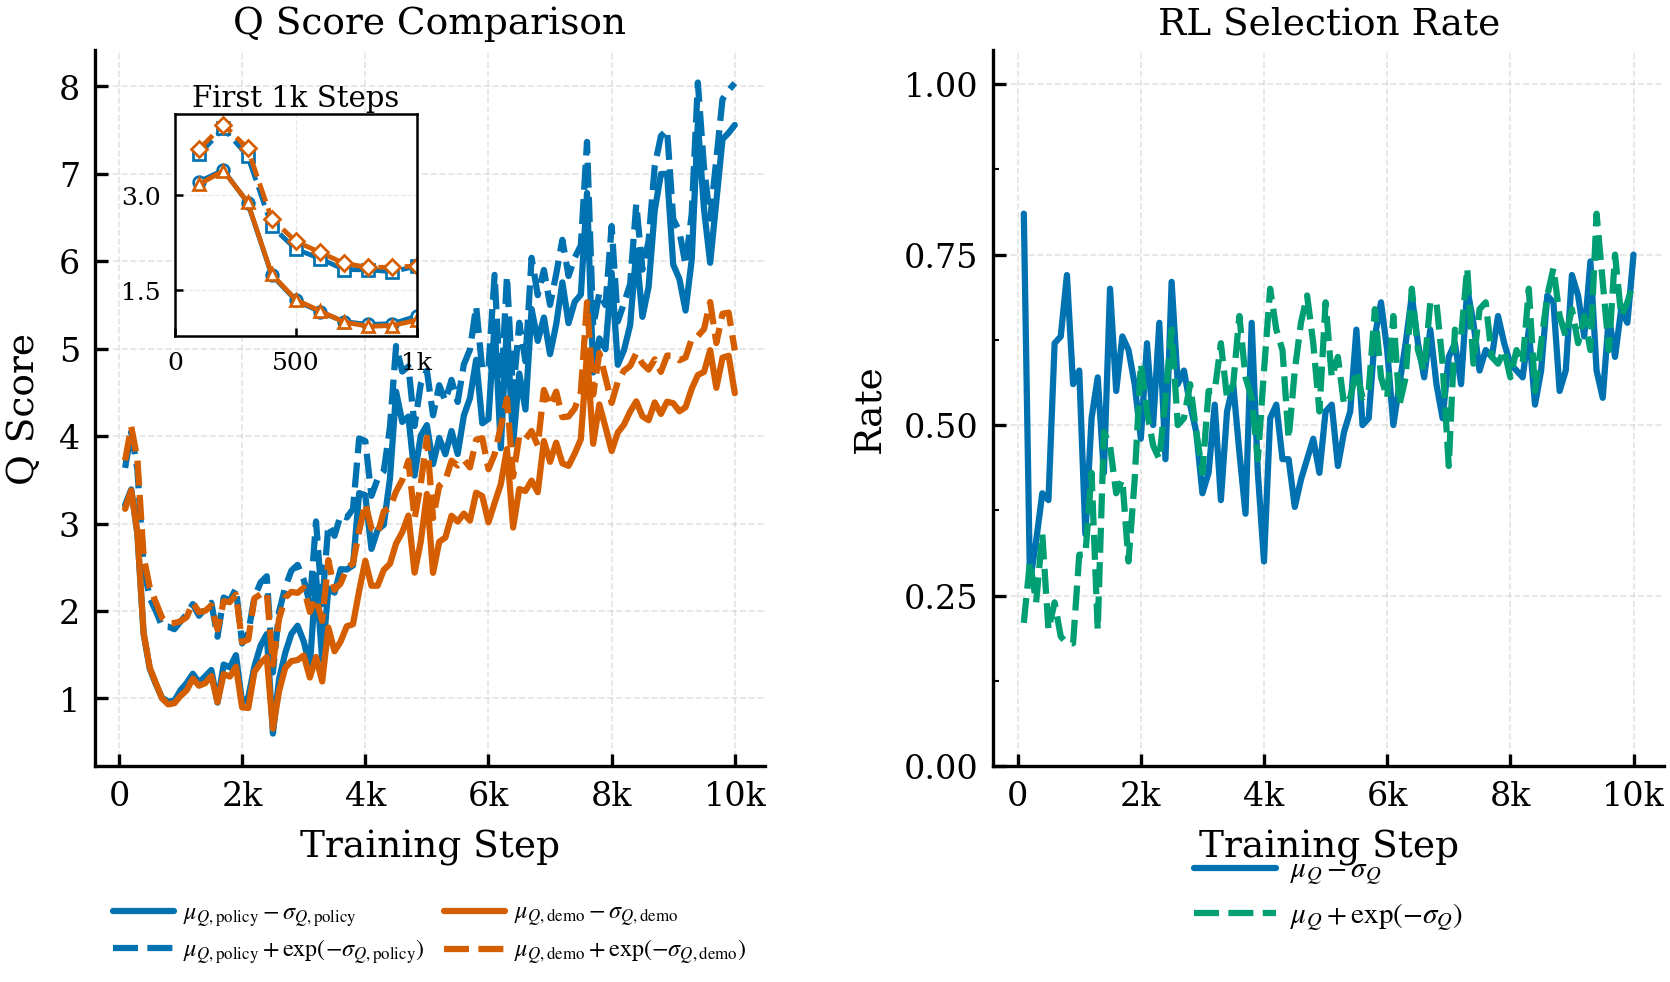

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from scipy.ndimage import uniform_filter1d


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def smooth(x, w=7):
    x = np.asarray(x, dtype=float)
    if len(x) < w:
        return x
    return uniform_filter1d(x, size=w, mode="nearest")


def aggregate_runs(dfs):
    """
    Merge runs by common training steps and compute mean/std.
    """
    merged = None

    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(
            columns={"Value": f"v{i}"}
        )

        if merged is None:
            merged = tmp
        else:
            merged = pd.merge(
                merged,
                tmp,
                on="Step",
                how="inner"
            )

    merged = merged.sort_values("Step")

    steps = merged["Step"].to_numpy()

    values = merged.drop(
        columns=["Step"]
    ).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


# ══════════════════════════════════════════════════════════════════════════
# LOAD reward DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen reward ----------------
df101 = pd.read_csv("./results/openbox/Q_compare/nn2.40_mean_demo.csv")
df102 = pd.read_csv("./results/openbox/Q_compare/nn2.40_mean_policy.csv")

df111 = pd.read_csv("./results/openbox/Q_compare/nn2.40_std_demo.csv")
df112 = pd.read_csv("./results/openbox/Q_compare/nn2.40_std_policy.csv")

df211 = pd.read_csv("./results/openbox/Q_compare/nn2.20_select.csv")
df212 = pd.read_csv("./results/openbox/Q_compare/nn2.40_select.csv")
# ══════════════════════════════════════════════════════════════════════════
# COMPUTE THE FOUR CRITIC SCORES
# ══════════════════════════════════════════════════════════════════════════
def compute_scores(mean_df, std_df):
    merged = pd.merge(
        mean_df[["Step", "Value"]].rename(columns={"Value": "mu_q"}),
        std_df[["Step", "Value"]].rename(columns={"Value": "sigma_q"}),
        on="Step",
        how="inner",
        validate="one_to_one",
    ).sort_values("Step")

    steps = merged["Step"].to_numpy()
    mu_q = merged["mu_q"].to_numpy(dtype=float)
    sigma_q = merged["sigma_q"].to_numpy(dtype=float)
    return steps, mu_q - sigma_q, mu_q + np.exp(-10*sigma_q)


policy_steps, policy_minus_std, policy_plus_exp = compute_scores(df102, df112)
demo_steps, demo_minus_std, demo_plus_exp = compute_scores(df101, df111)

series = [
    (r"$\mu_{Q,\mathrm{policy}} - \sigma_{Q,\mathrm{policy}}$",
     policy_steps, policy_minus_std, "#0072B2", ()),
    (r"$\mu_{Q,\mathrm{policy}} + \exp(-\sigma_{Q,\mathrm{policy}})$",
     policy_steps, policy_plus_exp, "#0072B2", (4, 1.5)),
    (r"$\mu_{Q,\mathrm{demo}} - \sigma_{Q,\mathrm{demo}}$",
     demo_steps, demo_minus_std, "#D55E00", ()),
    (r"$\mu_{Q,\mathrm{demo}} + \exp(-\sigma_{Q,\mathrm{demo}})$",
     demo_steps, demo_plus_exp, "#D55E00", (4, 1.5)),
]


# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION-STYLE PLOT — NO VARIANCE BANDS
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.color": "#bbbbbb",
    "xtick.direction": "in",
    "ytick.direction": "in",
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

fig, axes = plt.subplots(1, 2, figsize=(6.75, 3.1))
fig.subplots_adjust(wspace=0.34)
ax = axes[0]

for label, steps, values, color, dashes in series:
    ax.plot(steps, values, color=color, linewidth=1.5, dashes=dashes,
            solid_capstyle="round", label=label, zorder=3)

# Zoomed comparison of the first 1k training steps
inset = ax.inset_axes([0.12, 0.60, 0.36, 0.31])
early_values = []
inset_markers = ["o", "s", "^", "D"]
for series_index, (label, steps, values, color, dashes) in enumerate(series):
    mask = steps <= 1000
    inset.plot(steps[mask], values[mask], color=color, linewidth=1.15,
               dashes=dashes, solid_capstyle="round",
               marker=inset_markers[series_index], markersize=2.8,
               markerfacecolor="white", markeredgewidth=0.65)
    early_values.append(values[mask])

early_values = np.concatenate(early_values)
early_min, early_max = early_values.min(), early_values.max()
early_pad = max(0.05 * (early_max - early_min), 0.05)
inset.set_xlim(0, 1000)
inset.set_ylim(early_min - early_pad, early_max + early_pad)
inset.set_xticks([0, 500, 1000], labels=["0", "500", "1k"])
inset.yaxis.set_major_locator(mticker.MaxNLocator(3))
inset.tick_params(axis="both", labelsize=6, length=2, width=0.6)
inset.set_title("First 1k Steps", fontsize=7, pad=2)
inset.grid(True, linestyle="--", linewidth=0.3, alpha=0.35)
for spine in inset.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.6)

ax.set_title("Q Score Comparison", pad=4)
ax.set_xlabel("Training Step")
ax.set_ylabel("Q Score")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x / 1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.31), ncol=2,
          frameon=False, fontsize=5.8, handlelength=2.5,
          columnspacing=0.8, labelspacing=0.35, handletextpad=0.4)

# RIGHT — RL selection rates for the two scoring rules
ax_rate = axes[1]
selection_series = [
    (r"$\mu_Q - \sigma_Q$", df211, "#0072B2", ()),
    (r"$\mu_Q + \exp(-\sigma_Q)$", df212, "#009E73", (4, 1.5)),
]

for label, df, color, dashes in selection_series:
    selection_data = df[["Step", "Value"]].sort_values("Step")
    ax_rate.plot(selection_data["Step"], selection_data["Value"],
                 color=color, linewidth=1.5, dashes=dashes,
                 solid_capstyle="round", label=label, zorder=3)

ax_rate.set_title("RL Selection Rate", pad=4)
ax_rate.set_xlabel("Training Step")
ax_rate.set_ylabel("Rate")
ax_rate.set_ylim(0, 1.05)
ax_rate.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x / 1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax_rate.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax_rate.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax_rate.tick_params(which="minor", length=1.5, width=0.5)
ax_rate.legend(loc="lower center", bbox_to_anchor=(0.5, -0.27), ncol=1,
               frameon=False, fontsize=7.0, handlelength=2.8,
               labelspacing=0.45, handletextpad=0.5)

out = "results/q_score_comparison"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()


SnapOpen: episode 0 (100 steps)
SnapOpen: episode 50 (100 steps)
OpenBox: episode 0 (24 steps)
OpenBox: episode 100 (100 steps)
SnapOpenNew left: episode 0 (100 steps)
SnapOpenNew right: episode 49 (100 steps)
Saved → demos/fx_snapopen_openbox_three_trajectory_comparison.png / .pdf


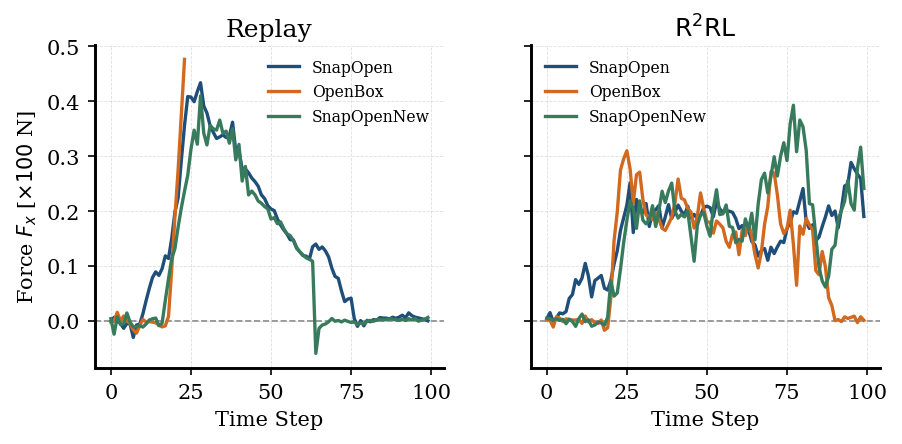

In [8]:
"""
Force-X Wrench Comparison Visualiser
====================================
Plots three trajectories in each subplot.

Left:
    1. FILE_PATH1
    2. FILE_PATH3, episode 0
    3. FILE_PATH4, episode 0

Right:
    1. FILE_PATH2
    2. FILE_PATH3, episode 100
    3. FILE_PATH4, episode 100
"""

import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════

FILE_PATH1 = "./demos/memories/replay_.csv"
LABEL1 = "SnapOpen"

FILE_PATH2 = "./demos/memories/snapopen_OSRL.csv"
LABEL2 = "SnapOpen"

FILE_PATH3 = "./demos/memories/nn2.40_openbox.csv"
LABEL3_LEFT = "OpenBox"
LABEL3_RIGHT = "OpenBox"

FILE_PATH4 = "./demos/residual_rl/memories/5.csv"
# FILE_PATH4 = "./demos/residual_rl/memories/train_offline.csv"
LABEL4 = "SnapOpenNew"

FILE_PATH5 = "./demos/memories/2.71.csv"
# FILE_PATH4 = "./demos/residual_rl/memories/train_offline.csv"
LABEL5 = "SnapOpenNew"

# Episode indices
FILE1_EPISODE = 0
FILE2_EPISODE = 50
FILE5_EPISODE = 72

# File 3 contributes one trajectory to each subplot
FILE3_LEFT_EPISODE = 0
FILE3_RIGHT_EPISODE = 100

# File 4 also contributes one trajectory to each subplot
FILE4_LEFT_EPISODE = 0
FILE4_RIGHT_EPISODE = 100


# Force columns
COL_FX = "observations.6"
COL_FY = "observations.7"
COL_FZ = "observations.8"

# Torque columns
COL_TX = "observations.9"
COL_TY = "observations.10"
COL_TZ = "observations.11"


# Colours
C_LINE1 = "#1F4E79"  # Blue
C_LINE2 = "#D2691E"  # Orange
C_LINE3 = "#387B5C"  # Green — FILE_PATH4


# ═══════════════════════════════════════════════════════════════════════════
# STYLE
# ═══════════════════════════════════════════════════════════════════════════

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Palatino Linotype",
        "Palatino",
        "Georgia",
        "DejaVu Serif",
    ],
    "axes.linewidth": 1.4,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})


# ═══════════════════════════════════════════════════════════════════════════
# HELPERS
# ═══════════════════════════════════════════════════════════════════════════

def load_and_split(path: str) -> list[pd.DataFrame]:
    """Load a CSV file and split it into episodes."""

    df = pd.read_csv(path)

    for column in ("truncated.0", "terminated.0", "useRL.0"):
        if column in df.columns:
            df[column] = df[column].astype(int)

    boundary_columns = {"truncated.0", "terminated.0"}

    if boundary_columns.issubset(df.columns):
        episode_end = (
            (df["truncated.0"] == 1)
            | (df["terminated.0"] == 1)
        ).astype(int)

        episode_ids = episode_end.shift(
            1,
            fill_value=0,
        ).cumsum()

        return [
            episode.reset_index(drop=True)
            for _, episode in df.groupby(episode_ids)
        ]

    return [df.reset_index(drop=True)]


def select_episode(
    episodes: list[pd.DataFrame],
    requested_idx: int,
) -> tuple[pd.DataFrame, int]:
    """Safely select an episode without exceeding the available range."""

    if not episodes:
        raise ValueError("The dataset does not contain any episodes.")

    safe_idx = min(
        max(requested_idx, 0),
        len(episodes) - 1,
    )

    return episodes[safe_idx], safe_idx


def extract_wrench(ep: pd.DataFrame):
    """Extract forces and torques from an episode."""

    steps = np.arange(len(ep))

    force_columns = {COL_FX, COL_FY, COL_FZ}

    if force_columns.issubset(ep.columns):
        fx = ep[COL_FX].to_numpy(dtype=float)
        fy = ep[COL_FY].to_numpy(dtype=float)
        fz = ep[COL_FZ].to_numpy(dtype=float)
    else:
        print("⚠ Warning: Force columns not found. Filling with zeros.")
        fx = np.zeros(len(ep))
        fy = np.zeros(len(ep))
        fz = np.zeros(len(ep))

    torque_columns = {COL_TX, COL_TY, COL_TZ}

    if torque_columns.issubset(ep.columns):
        tx = ep[COL_TX].to_numpy(dtype=float)
        ty = ep[COL_TY].to_numpy(dtype=float)
        tz = ep[COL_TZ].to_numpy(dtype=float)
    else:
        print("⚠ Warning: Torque columns not found. Filling with zeros.")
        tx = np.zeros(len(ep))
        ty = np.zeros(len(ep))
        tz = np.zeros(len(ep))

    return steps, fx, fy, fz, tx, ty, tz


# ═══════════════════════════════════════════════════════════════════════════
# LOAD DATASETS
# ═══════════════════════════════════════════════════════════════════════════

episodes1 = load_and_split(FILE_PATH1)
episodes2 = load_and_split(FILE_PATH2)
episodes3 = load_and_split(FILE_PATH3)
episodes4 = load_and_split(FILE_PATH4)
episodes5 = load_and_split(FILE_PATH5)


# File 1
ep1, idx1 = select_episode(
    episodes1,
    FILE1_EPISODE,
)

steps1, fx1, fy1, fz1, tx1, ty1, tz1 = extract_wrench(ep1)


# File 2
ep2, idx2 = select_episode(
    episodes2,
    FILE2_EPISODE,
)

steps2, fx2, fy2, fz2, tx2, ty2, tz2 = extract_wrench(ep2)

# File 5
ep5, idx5 = select_episode(
    episodes5,
    FILE5_EPISODE,
)
steps5, fx5, fy5, fz5, tx5, ty5, tz5 = extract_wrench(ep5)

# File 3 — left trajectory
ep3_left, idx3_left = select_episode(
    episodes3,
    FILE3_LEFT_EPISODE,
)

(
    steps3_left,
    fx3_left,
    fy3_left,
    fz3_left,
    tx3_left,
    ty3_left,
    tz3_left,
) = extract_wrench(ep3_left)


# File 3 — right trajectory
ep3_right, idx3_right = select_episode(
    episodes3,
    FILE3_RIGHT_EPISODE,
)

(
    steps3_right,
    fx3_right,
    fy3_right,
    fz3_right,
    tx3_right,
    ty3_right,
    tz3_right,
) = extract_wrench(ep3_right)


# File 4 — third trajectory on the left
ep4_left, idx4_left = select_episode(
    episodes4,
    FILE4_LEFT_EPISODE,
)

(
    steps4_left,
    fx4_left,
    fy4_left,
    fz4_left,
    tx4_left,
    ty4_left,
    tz4_left,
) = extract_wrench(ep4_left)


# File 4 — third trajectory on the right
ep4_right, idx4_right = select_episode(
    episodes4,
    FILE4_RIGHT_EPISODE,
)

(
    steps4_right,
    fx4_right,
    fy4_right,
    fz4_right,
    tx4_right,
    ty4_right,
    tz4_right,
) = extract_wrench(ep4_right)


# Print selected episodes
print(f"{LABEL1}: episode {idx1} ({len(ep1)} steps)")
print(f"{LABEL2}: episode {idx2} ({len(ep2)} steps)")

print(
    f"{LABEL3_LEFT}: episode {idx3_left} "
    f"({len(ep3_left)} steps)"
)
print(
    f"{LABEL3_RIGHT}: episode {idx3_right} "
    f"({len(ep3_right)} steps)"
)

print(
    f"{LABEL4} left: episode {idx4_left} "
    f"({len(ep4_left)} steps)"
)
print(
    f"{LABEL4} right: episode {idx4_right} "
    f"({len(ep4_right)} steps)"
)


# ═══════════════════════════════════════════════════════════════════════════
# SIDE-BY-SIDE FORCE-X COMPARISON
# ═══════════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.75, 2.8),
    sharey=True,
    facecolor="white",
)

fig.subplots_adjust(wspace=0.25)


# LEFT — three trajectories
axes[0].plot(
    steps1,
    fx1,
    color=C_LINE1,
    linewidth=1.6,
    label=LABEL1,
    zorder=3,
)

axes[0].plot(
    steps3_left,
    fx3_left,
    color=C_LINE2,
    linewidth=1.6,
    label=LABEL3_LEFT,
    zorder=3,
)

axes[0].plot(
    steps4_right,
    fx4_right,
    color=C_LINE3,
    linewidth=1.6,
    label=LABEL4,
    zorder=3,
)

axes[0].set_title("Replay", pad=4)
axes[0].set_ylabel(r"Force $F_x$ [$\times 100$ N]")


# RIGHT — three trajectories
axes[1].plot(
    steps2,
    fx2,
    color=C_LINE1,
    linewidth=1.6,
    label=LABEL2,
    zorder=3,
)

axes[1].plot(
    steps3_right,
    fx3_right,
    color=C_LINE2,
    linewidth=1.6,
    label=LABEL3_RIGHT,
    zorder=3,
)

axes[1].plot(
    steps5,
    fx5,
    color=C_LINE3,
    linewidth=1.6,
    label=LABEL4,
    zorder=3,
)

axes[1].set_title(r"$\mathrm{R}^{2}\mathrm{RL}$", pad=4)


# Shared formatting
for ax in axes:
    ax.axhline(
        0,
        color="#888888",
        linewidth=0.8,
        linestyle="--",
        zorder=1,
    )

    ax.set_xlabel("Time Step")

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.4,
        alpha=0.4,
    )

    ax.legend(
        loc="best",
        fontsize=7.5,
        frameon=False,
    )


# ═══════════════════════════════════════════════════════════════════════════
# SAVE
# ═══════════════════════════════════════════════════════════════════════════

SAVE_DIR = "demos"
os.makedirs(SAVE_DIR, exist_ok=True)

out = os.path.join(
    SAVE_DIR,
    "fx_snapopen_openbox_three_trajectory_comparison",
)

fig.savefig(
    f"{out}.png",
    facecolor="white",
)

fig.savefig(
    f"{out}.pdf",
    facecolor="white",
)

print(f"Saved → {out}.png / .pdf")

plt.show()